# Forest Cover Type Classification - Exploratory Data Analysis

This notebook is the first stage of a machine learning project investigating model generalization and robustness on the Forest Cover Type dataset.

The objective is to understand the dataset's structure, identify potentially informative features, and investigate statistical relationships that may influence subsequent modeling decisions.

The next stages will focus on preprocessing, baseline model comparison, overfitting, and out-of-sample evaluation.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.feature_selection import mutual_info_classif

In [3]:
df = pd.read_csv("../data/train.csv")

Let us conduct a first basic analysis of our dataset. The goal here is to grasp the overall structure of the dataset we are dealing with.

In [4]:
df.head()

,Id,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,...,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Cover_Type
0,242642,2881,130,22,210,54,1020,250,221,88,...,0,0,0,0,0,0,0,0,0,1
1,309891,3005,351,14,242,-16,1371,194,215,159,...,0,0,0,0,0,0,0,0,0,1
2,287847,3226,63,14,618,2,1092,232,210,107,...,0,0,0,0,0,0,0,0,0,1
3,516307,3298,317,8,661,60,752,198,233,174,...,0,0,0,0,0,0,0,0,0,1
4,124860,3080,35,6,175,26,3705,219,227,144,...,0,0,0,0,0,0,0,0,0,1


In [5]:
print(f"The dataset is composed of {df.shape[0]} samples and {df.shape[1]-2} features.")

The dataset is composed of 15120 samples and 54 features.


In [6]:
print(df.dtypes.value_counts())
print(df.nunique())

int64    56
Name: count, dtype: int64
Id                                    15120
Elevation                              1676
Aspect                                  361
Slope                                    51
Horizontal_Distance_To_Hydrology        397
Vertical_Distance_To_Hydrology          433
Horizontal_Distance_To_Roadways        3274
Hillshade_9am                           176
Hillshade_Noon                          140
Hillshade_3pm                           248
Horizontal_Distance_To_Fire_Points     2764
Wilderness_Area1                          2
Wilderness_Area2                          2
Wilderness_Area3                          2
Wilderness_Area4                          2
Soil_Type1                                2
Soil_Type2                                2
Soil_Type3                                2
Soil_Type4                                2
Soil_Type5                                2
Soil_Type6                                2
Soil_Type7                            

We can easily guess, according to the number of unique values present in the columns, which features are continous, and which are categorical. 

In [7]:
n_categorical = int((df.nunique() < 10).sum())
n_continuous = df.shape[1]-n_categorical
print (f"The number of categorical variables is {n_categorical}.")
print (f"The number of continous variables is {n_continuous}.")

The number of categorical variables is 45.
The number of continous variables is 11.


Among our 54 features, we have 44 features that are binary, and more precisely, binary, as it has been binarly encoded. Our response variable, Cover_Type, is also categorical, and can take 7 different values. We thus face a classification problem here.

In [8]:
print (f"The number of N/A is {int(df.isna().sum().sum())}")
            
print (f"The number of duplicated is {int(df.duplicated().sum())}")

The number of N/A is 0
The number of duplicated is 0


In [9]:
df.describe()

,Id,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,...,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Cover_Type
count,15120.000000,15120.000000,15120.000000,15120.000000,15120.000000,15120.000000,15120.000000,15120.000000,15120.000000,15120.000000,...,15120.000000,15120.000000,15120.000000,15120.000000,15120.000000,15120.000000,15120.000000,15120.000000,15120.000000,15120.000000
mean,267008.526389,2748.649934,155.834524,16.556746,228.376521,51.311706,1717.977712,213.028836,218.865741,134.477116,...,0.043849,0.040939,0.001190,0.006812,0.000926,0.002116,0.049206,0.041931,0.030159,4.000000
std,179261.722330,419.009589,109.745372,8.534602,209.196381,61.520488,1330.263450,30.638406,22.797288,46.070054,...,0.204766,0.198156,0.034484,0.082257,0.030416,0.045957,0.216306,0.200439,0.171030,2.000066
min,5.000000,1877.000000,0.000000,0.000000,0.000000,-135.000000,0.000000,52.000000,99.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,103705.000000,2373.000000,65.000000,10.000000,67.000000,5.000000,760.000000,197.000000,207.000000,106.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000
50%,276034.500000,2754.000000,125.000000,15.000000,180.000000,32.000000,1315.000000,220.000000,223.000000,138.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.000000
75%,398150.250000,3109.000000,257.000000,22.000000,330.000000,80.000000,2292.000000,236.000000,235.000000,166.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000
max,581005.000000,3850.000000,360.000000,50.000000,1376.000000,570.000000,6803.000000,254.000000,254.000000,251.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,7.000000


Some values are extreme, but we will remove them from the dataset only if we have evidence of an error of measurement.

In [10]:
for prefix in ["Wilderness_Area", "Soil_Type"]:
    mask = df.columns.str.startswith(prefix)
    print(prefix, df[df.columns[mask]].sum(axis=1).value_counts())

Wilderness_Area 1    15120
Name: count, dtype: int64
Soil_Type 1    15120
Name: count, dtype: int64


There are as many 1s in the categorical features WIlderness_Area and Soil_Type as there are samples, which means that each observation  belongs to one single type of Wilderness_Area, and one single of Soil_Type. 
This is coherent and substantial for our future classification models.

From now on, let us split our data into a training set and test set that we will keep separated.

In [11]:
df_train, df_test = train_test_split(
    df, 
    test_size=0.2, 
    stratify=df["Cover_Type"], 
    random_state=42)

Are the modalities of the response variable well-balanced, or are there any modalities that represent the vast majority ?

<Axes: xlabel='Cover_Type', ylabel='count'>

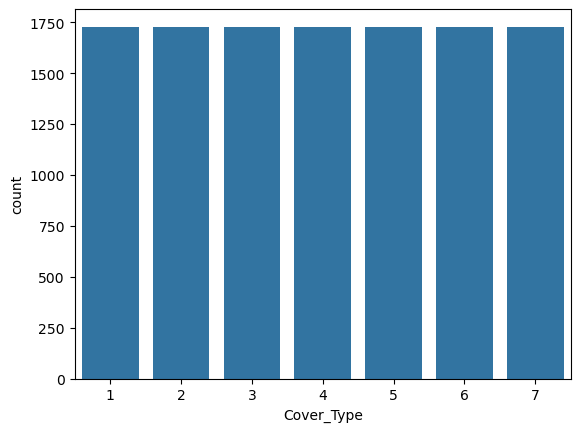

In [12]:
import seaborn as sns
sns.countplot(data=df_train, x="Cover_Type")

The modalities are perfectly balanced, which will spare us future problems in our classification models, such as the issue of the model not learning the data and still having a high accuracy score.

Let us now dive a little deeper into our dataset and check whether correlation trends between features can be identified.

<Axes: >

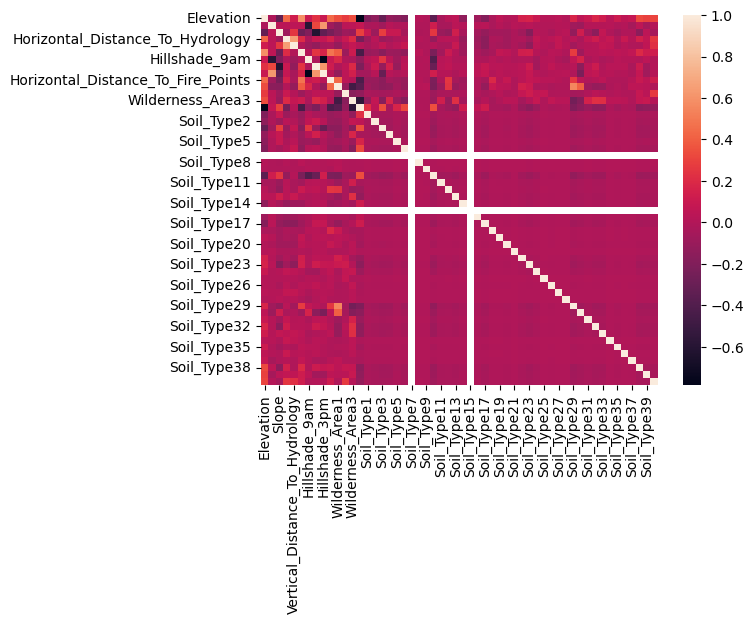

In [13]:
X = df_train.drop(columns=["Id", "Cover_Type"])
corr = X.corr()
sns.heatmap(corr)


The correlation matrix exhibits weak correlation between features, with a few notable exceptions. This suggests limited pairwise redundancy.
However, weak pairwise correlations do not allow us to exclude a possibility of multi-collinearity. One feature could be the sum of the other independent features.
Let us check what these few exceptions of weak pairwise correlation are.

In [14]:
min_corr = corr.mask(np.eye(len(corr), dtype=bool)).min().min()
max_corr = corr.mask(np.eye(len(corr), dtype=bool)).max().max()

arr_min = np.where(corr == min_corr) #The matrix is symmetric, so there are two arrays meeting the conditions. We only need one to determine the couple of features with the lower correlation.
arr_max = np.where(corr == max_corr)

print(f"The variables who are strongly negatively correlated are {tuple(corr.index[arr_min[0]])} with a correlation of {min_corr}")
print(f"The variables who are sttongly positevly correlated are {tuple(corr.index[arr_max[0]])} with a correlation of {max_corr}")

The variables who are strongly negatively correlated are ('Elevation', 'Wilderness_Area4') with a correlation of -0.7821180957338508
The variables who are sttongly positevly correlated are ('Horizontal_Distance_To_Hydrology', 'Vertical_Distance_To_Hydrology') with a correlation of 0.6502257373826483


We can see that some features are highly correlated or highly uncorrelated. When looking at the variables involded, we can suppose that these correlations are not due to error in the data, but to geographical and natural reasons instead. We can guess that Wilderness_Area4 is a low-altitude habitat, and the further you are from a water point, the more likely you are located on a different altitude, as water points mostly are located on a single fixed altitude. 

Now, let us check which features have the strongest individual statistical association with the response variable Cover_Type.

In [15]:
discrete = X.columns.str.startswith(("Wilderness_Area", "Soil_Type"))
mi = mutual_info_classif(X, df_train["Cover_Type"], discrete_features=discrete, random_state=42)
mi_scores = pd.Series(mi, index=X.columns).sort_values(ascending=False)
mi_scores

Elevation                             1.022762
Wilderness_Area4                      0.416381
Horizontal_Distance_To_Roadways       0.320451
Horizontal_Distance_To_Fire_Points    0.197174
Wilderness_Area1                      0.173056
Horizontal_Distance_To_Hydrology      0.140370
Soil_Type10                           0.136020
Hillshade_9am                         0.110617
Wilderness_Area3                      0.100425
Soil_Type3                            0.100298
Vertical_Distance_To_Hydrology        0.084545
Soil_Type38                           0.081995
Slope                                 0.075801
Aspect                                0.074502
Soil_Type39                           0.069990
Soil_Type29                           0.067062
Hillshade_3pm                         0.061422
Soil_Type30                           0.052949
Soil_Type40                           0.049311
Soil_Type4                            0.036715
Wilderness_Area2                      0.036634
Soil_Type6   

<Axes: xlabel='Cover_Type', ylabel='Horizontal_Distance_To_Fire_Points'>

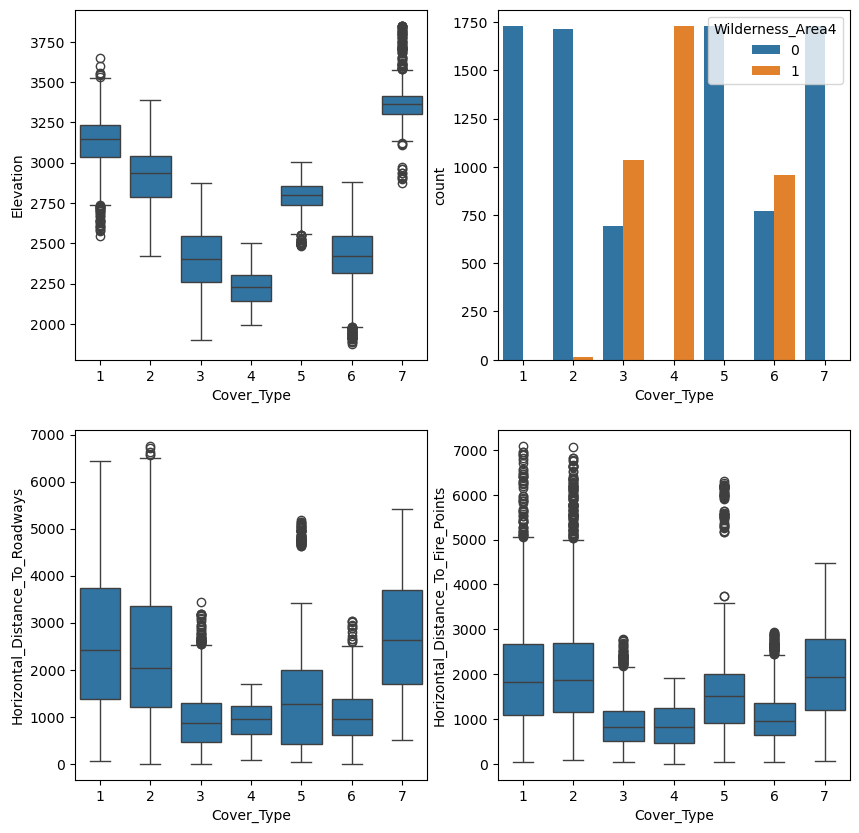

In [16]:
fig, axes = plt.subplots(2,2, figsize=(10,10))
sns.boxplot(df_train, x="Cover_Type", y="Elevation", ax=axes[0,0])
sns.countplot(df_train, x="Cover_Type", hue="Wilderness_Area4", ax=axes[0,1])
sns.boxplot(df_train, x="Cover_Type", y="Horizontal_Distance_To_Roadways", ax=axes[1,0])
sns.boxplot(df_train, x="Cover_Type", y="Horizontal_Distance_To_Fire_Points", ax=axes[1,1])

Elevation exhibits distinct distributions across forest cover types, suggesting substantial individual discriminatory power. In particular, Cover Type 7 tends to occur at higher elevations, whereas Cover Type 4 is associated with lower elevations.

However, the overlap between several class distributions suggests that elevation alone may not be sufficient for accurate classification. This motivates evaluating a baseline model using Elevation only, before comparing it with models incorporating additional environmental features.

This exploratory analysis highlights several important facts on our dataset:

1) The response variable is a categorical variable whose modalities are well-balanced. The stratified test_train_split keeps this balance intact. 

2) Some features exhibit statiscal association with the response variable, particularly Elevation and Wilderness_Area4

2) Many features have overlapping distributions, implying that feature engineering could improve results.

3) Some features are correlated, suggesting probable redundancy.